Predict future averge price of Pulses and Nuts monthly by using SARIMAX model and Linear Regression Model
* According to the result, SARIMAX is better. But we can't tell exactly because of the causes of Covid 19 and Political changes

### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# LinearRegression
from sklearn.linear_model import LinearRegression

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

In [7]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [8]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2009-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [9]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [10]:
data.shape

(31972, 14)

In [11]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [12]:
DPNM = data.copy()
DPNM = DPNM[DPNM['category']=='pulses and nuts']
DPNM.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
16,1/15/2008,Rakhine,Maungdaw,Alel Than Kyaw,pulses and nuts,Chickpeas (local),local,NaN,KG,actual,Retail,MMK,650.0,0.3652
19,1/15/2008,Rakhine,Maungdaw,Buthidaung,pulses and nuts,Chickpeas (local),local,NaN,KG,actual,Retail,MMK,600.0,0.3371
22,1/15/2008,Rakhine,Maungdaw,Kyein Chung,pulses and nuts,Chickpeas (local),local,NaN,KG,actual,Retail,MMK,500.0,0.2809
25,1/15/2008,Rakhine,Maungdaw,Maungdaw,pulses and nuts,Chickpeas (local),local,NaN,KG,actual,Retail,MMK,570.0,0.3202
28,1/15/2008,Rakhine,Maungdaw,Myin Hlut,pulses and nuts,Chickpeas (local),local,NaN,KG,actual,Retail,MMK,450.0,0.2528


In [13]:
DPNM = DPNM[['date', 'price']]
DPNM['date'] = pd.to_datetime(DPNM['date'])
mask = (DPNM['date']>=obv_st_date) & (DPNM['date']<=obv_end_date)
DPNM = DPNM.loc[mask]
DPNM = DPNM.set_index('date')
DPNM.head()

,price
date,
2008-01-15,650.0
2008-01-15,600.0
2008-01-15,500.0
2008-01-15,570.0
2008-01-15,450.0


In [14]:
DPNM = DPNM.resample('MS').mean()
DPNM.head()

,price
date,
2008-01-01,623.095714
2008-02-01,800.952143
2008-03-01,835.064286
2008-04-01,597.618571
2008-05-01,531.092857


In [15]:
DPNM.shape

(169, 1)

In [16]:
price = DPNM['price']
date = DPNM.index

##### Normalization data

In [17]:
scaler = MinMaxScaler()

In [18]:
DPNM_nor = scaler.fit_transform(DPNM)
DPNM_nor = pd.DataFrame(DPNM_nor)
DPNM_nor.head()

,0
0,0.052446
1,0.153832
2,0.173278
3,0.037923
4,0.000000


In [19]:
DPNM_nor['date']=date
DPNM_nor = DPNM_nor.set_index('date')
DPNM_nor.columns=['price']
DPNM_nor.head()

,price
date,
2008-01-01,0.052446
2008-02-01,0.153832
2008-03-01,0.173278
2008-04-01,0.037923
2008-05-01,0.000000


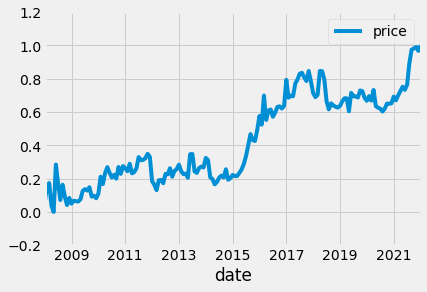

In [20]:
DPNM_nor.plot(grid=True)
plt.show()

It has positive trend.

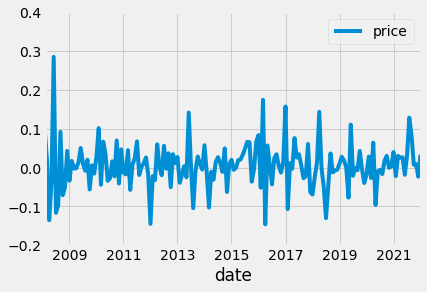

In [21]:
DPNM_nor_diff1 = DPNM_nor.diff(1).dropna()
DPNM_nor_diff1.plot(grid=True)
plt.show()

##### Checking Random Walk

In [22]:
RW_DPNM= adfuller(DPNM_nor_diff1)
RW_DPNM[1] # print P-value. If p-value<5%, reject null hypothesis

1.2498850271734752e-28

<span style="color:red">Are there any external factors that may influence this price?</span>

##### Plotting ACF and PACF

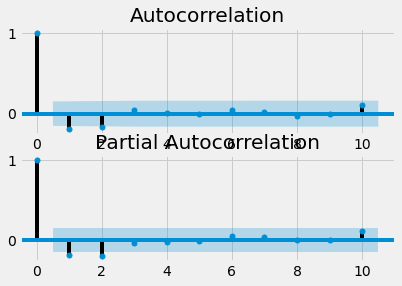

In [23]:
fig, axes=plt.subplots(2,1)
plot_acf(DPNM_nor_diff1, lags=10, ax=axes[0])
plot_pacf(DPNM_nor_diff1, lags=10, ax=axes[1])
plt.show()

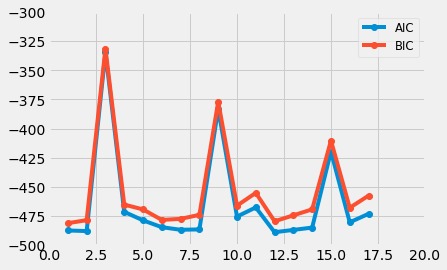

In [24]:
AIC, BIC = AIC_BIC_withOrderRange(DPNM_nor_diff1, p=3, d=2, q=3)
# 0:(0,0,0), 1:(0,0,1), 2:(0,0,2), 3:(0,1,0), 4:(0,1,1), 5:(0,1,2), 
# 6:(1,0,0), 7:(1,0,1), 8:(1,0,2), 9:(1,1,0), 10:(1,1,1), 11:(1,1,2), 
# 12:(2,0,0), 13:(2,0,1), 14:(2,0,2), 15:(2,1,0), 16:(2,1,1), 17:(2,1,2)

In [25]:
AIC, BIC

(array([-480.70649697, -487.28422559, -487.80647914, -334.54470863,
        -471.32465612, -478.62050549, -484.48064546, -486.69732187,
        -486.37229656, -383.10263466, -475.36794069, -467.52913246,
        -488.78367472, -486.80297793, -484.80466858, -419.59864912,
        -480.278374  , -473.0329897 ]),
 array([-477.58253299, -481.03629763, -478.4345872 , -331.42671481,
        -465.0886685 , -469.26652405, -478.2327175 , -477.32542993,
        -473.87644064, -376.86664704, -466.01395925, -455.05715721,
        -479.41178279, -474.30712202, -469.18484868, -410.24466769,
        -467.80639875, -457.44302064]))

We will run again 1:(0,0,1), 2:(0,0,2), 6:(1,0,0), 7:(1,0,1), 8:(1,0,2), 11:(1,1,2)

In [26]:
mod_orders = [
    (0,0,1), #0
    (0,0,2), #1
    (1,0,0), #2
    (1,0,1), #3
    (1,0,2), #4
]
mod_diff_orders = [
    (1,1,2) #5
]

In [27]:
DPNM_models = []

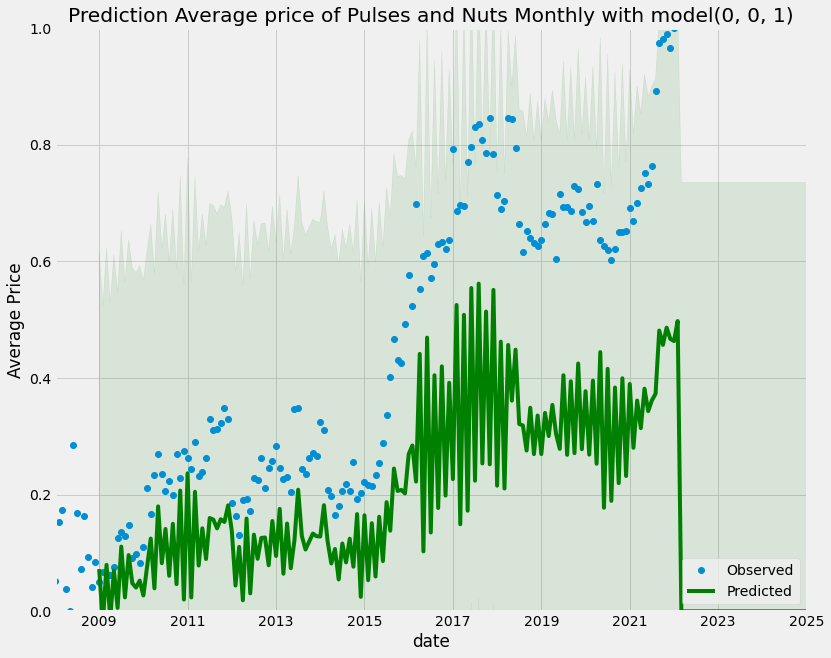

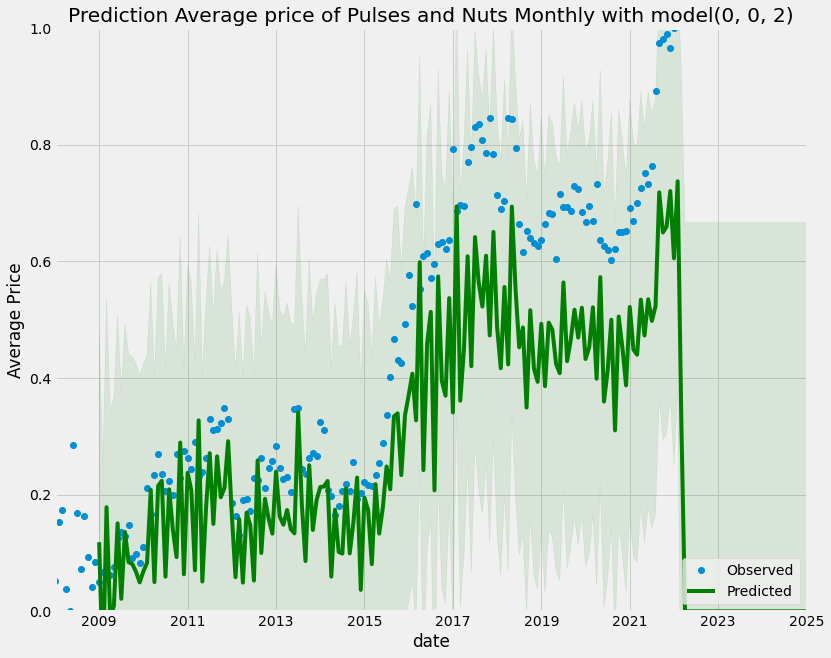

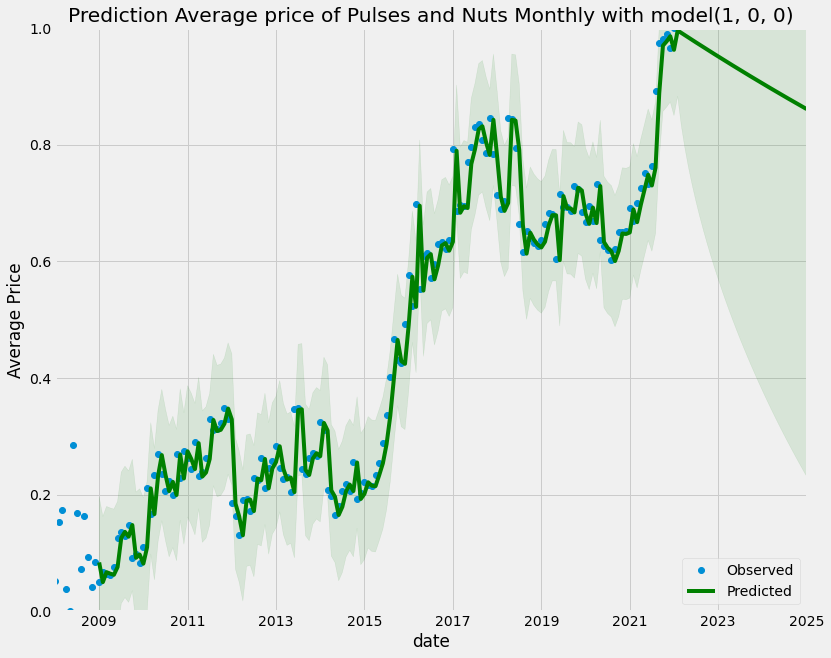

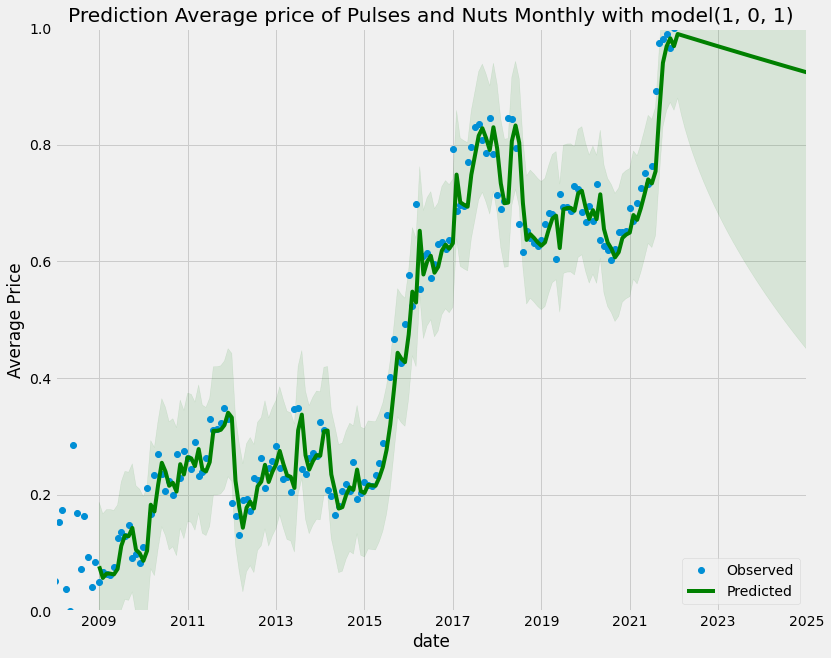

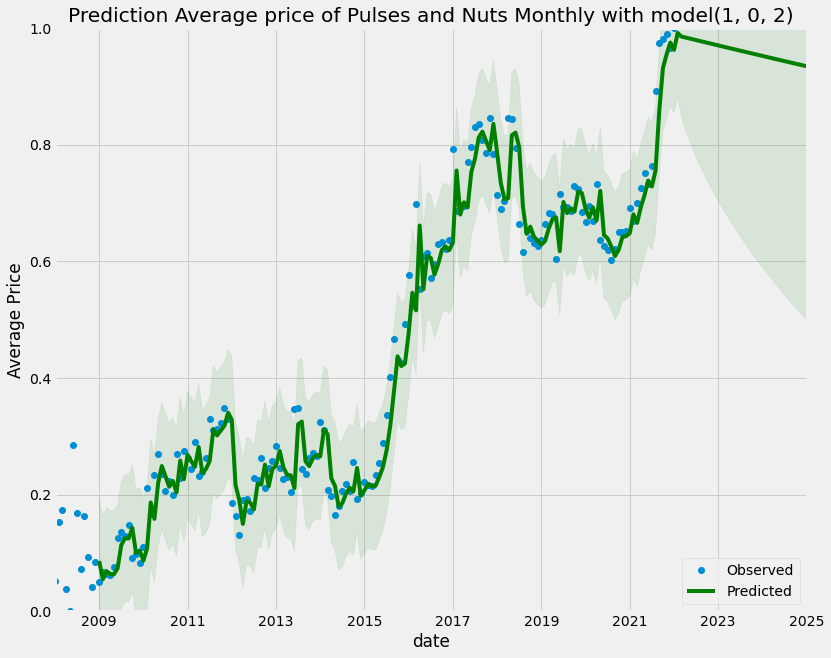

In [28]:
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DPNM_nor, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Pulses and Nuts Monthly with model'+str(order), xlabel='Date', ylabel='Average Price')
    DPNM_models.append(model)

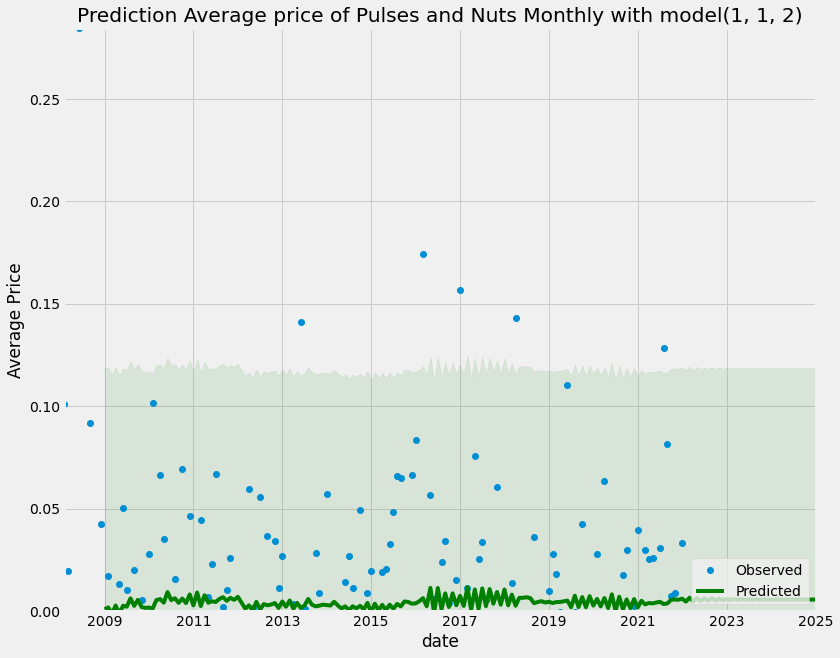

In [29]:
for ind, order in enumerate(mod_diff_orders): 
    model = Run_SARIMAX(DPNM_nor_diff1, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Pulses and Nuts Monthly with model'+str(order), xlabel='Date', ylabel='Average Price')
    DPNM_models.append(model)

Now we choose (1,0,1)

In [30]:
DPNM_model = DPNM_models[3]

In [31]:
DPNM_pred_normalized = DPNM_model.predict(pred_st_date, pred_end_date)
DPNM_pred_normalized 

2009-01-01    0.077215
2009-02-01    0.057205
2009-03-01    0.064560
2009-04-01    0.064601
2009-05-01    0.063216
                ...   
2024-09-01    0.931468
2024-10-01    0.929642
2024-11-01    0.927820
2024-12-01    0.926002
2025-01-01    0.924187
Freq: MS, Length: 193, dtype: float64

In [32]:
mask = (DPNM_nor.index>=pred_st_date) & (DPNM_nor.index<=pred_end_date)
DPNM_pred = DPNM_nor.loc[mask]
DPNM_pred

,price
date,
2009-01-01,0.050187
2009-02-01,0.067368
2009-03-01,0.064788
2009-04-01,0.062888
2009-05-01,0.076189
...,...
2021-09-01,0.973945
2021-10-01,0.981257
2021-11-01,0.990148


We need to un-normalized the predicted value to get actual price

In [33]:
pred_date = DPNM_pred_normalized.index
pred_date = pred_date[:-1] # the last index doesn't need
pred_date

DatetimeIndex(['2009-01-01', '2009-02-01', '2009-03-01', '2009-04-01',
               '2009-05-01', '2009-06-01', '2009-07-01', '2009-08-01',
               '2009-09-01', '2009-10-01',
               ...
               '2024-03-01', '2024-04-01', '2024-05-01', '2024-06-01',
               '2024-07-01', '2024-08-01', '2024-09-01', '2024-10-01',
               '2024-11-01', '2024-12-01'],
              dtype='datetime64[ns]', length=192, freq='MS')

In [34]:
DPNM_pred_normalized_df = pd.DataFrame(DPNM_pred_normalized)
DPNM_pred_normalized_df = DPNM_pred_normalized_df[:-1] # the last index doesn't need
DPNM_pred_normalized_df

,0
2009-01-01,0.077215
2009-02-01,0.057205
2009-03-01,0.064560
2009-04-01,0.064601
2009-05-01,0.063216
...,...
2024-08-01,0.933297
2024-09-01,0.931468
2024-10-01,0.929642
2024-11-01,0.927820


##### Un-normalization data

In [35]:
DPNM_pred_act = scaler.inverse_transform(DPNM_pred_normalized_df)
DPNM_pred_act_df = pd.DataFrame(DPNM_pred_act)
DPNM_pred_act_df['date'] = pred_date
DPNM_pred_act_df.columns = ['Predicted Price', 'date']
DPNM_pred_act_df.set_index('date',  inplace=True)
DPNM_pred_act_df

,Predicted Price
date,
2009-01-01,666.546472
2009-02-01,631.444879
2009-03-01,644.347113
2009-04-01,644.419203
2009-05-01,641.989054
...,...
2024-08-01,2168.321979
2024-09-01,2165.113170
2024-10-01,2161.910651


In [36]:
mask = (DPNM.index>=pred_st_date) & (DPNM.index<=pred_end_date)
DPNM_Act = DPNM.loc[mask]
DPNM_Act

,price
date,
2009-01-01,619.133571
2009-02-01,649.272857
2009-03-01,644.747333
2009-04-01,641.414000
2009-05-01,664.747333
...,...
2021-09-01,2239.628605
2021-10-01,2252.456044
2021-11-01,2268.051744


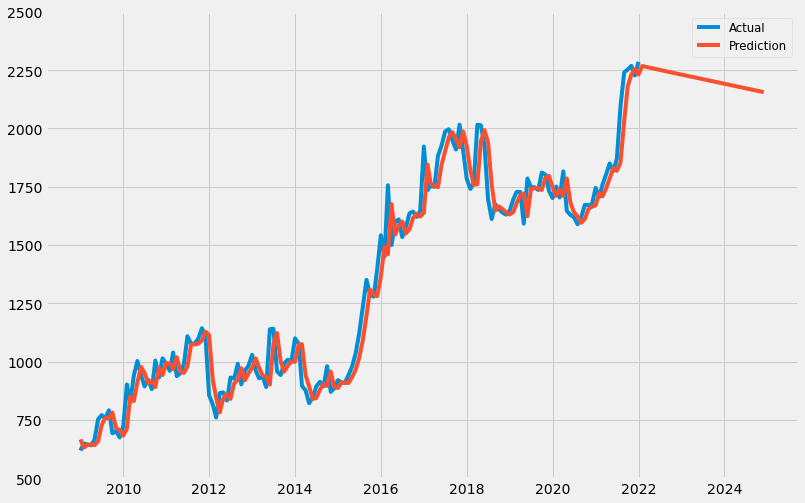

In [37]:
plt.figure(figsize=(12,8))
plt.plot(DPNM_Act, label="Actual")
plt.plot(DPNM_pred_act_df, label = "Prediction")
plt.legend(loc='best',fontsize='small')
plt.show()

### Linear Regression

In [38]:
temp_df = DPNM_nor.copy()
temp_df.reset_index(inplace =True)
temp_df

,date,price
0,2008-01-01,0.052446
1,2008-02-01,0.153832
2,2008-03-01,0.173278
3,2008-04-01,0.037923
4,2008-05-01,0.000000
...,...,...
164,2021-09-01,0.973945
165,2021-10-01,0.981257
166,2021-11-01,0.990148
167,2021-12-01,0.966719


In [39]:
temp_df['time'] = temp_df['date'].apply(lambda x: x.value)
mask = np.random.rand(len(temp_df)) < 0.8
train = temp_df[mask]
test = temp_df[~mask]
train, test

(          date     price                 time
 0   2008-01-01  0.052446  1199145600000000000
 1   2008-02-01  0.153832  1201824000000000000
 2   2008-03-01  0.173278  1204329600000000000
 3   2008-04-01  0.037923  1207008000000000000
 4   2008-05-01  0.000000  1209600000000000000
 ..         ...       ...                  ...
 164 2021-09-01  0.973945  1630454400000000000
 165 2021-10-01  0.981257  1633046400000000000
 166 2021-11-01  0.990148  1635724800000000000
 167 2021-12-01  0.966719  1638316800000000000
 168 2022-01-01  1.000000  1640995200000000000
 
 [144 rows x 3 columns],
           date     price                 time
 9   2008-10-01  0.092306  1222819200000000000
 13  2009-02-01  0.067368  1233446400000000000
 14  2009-03-01  0.064788  1235865600000000000
 34  2010-11-01  0.228726  1288569600000000000
 39  2011-04-01  0.231968  1301616000000000000
 50  2012-03-01  0.130863  1330560000000000000
 53  2012-06-01  0.172530  1338508800000000000
 57  2012-10-01  0.211679  134904

In [40]:
X_train = train.time
X_train = X_train.values.reshape((-1,1))
y_train = train['price'].values
X_train[:10], y_train[:10]

(array([[1199145600000000000],
        [1201824000000000000],
        [1204329600000000000],
        [1207008000000000000],
        [1209600000000000000],
        [1212278400000000000],
        [1214870400000000000],
        [1217548800000000000],
        [1220227200000000000],
        [1225497600000000000]], dtype=int64),
 array([0.05244592, 0.15383238, 0.1732779 , 0.03792276, 0.        ,
        0.28457326, 0.1681886 , 0.07171879, 0.16340713, 0.04143954]))

In [41]:
X_test = test.time
X_test = X_test.values.reshape((-1,1))
y_test = test['price'].values
X_test[:10], y_test[:10]

(array([[1222819200000000000],
        [1233446400000000000],
        [1235865600000000000],
        [1288569600000000000],
        [1301616000000000000],
        [1330560000000000000],
        [1338508800000000000],
        [1349049600000000000],
        [1356998400000000000],
        [1372636800000000000]], dtype=int64),
 array([0.09230562, 0.06736811, 0.06478835, 0.22872588, 0.23196815,
        0.13086309, 0.17252968, 0.21167878, 0.28418671, 0.34782273]))

In [42]:
X = np.concatenate((X_train, X_test), axis = 0)
y = np.concatenate((y_train, y_test), axis = 0)

In [43]:
DPNM_linreg = LinearRegression().fit(X_train, y_train)

In [44]:
print('linear model coeff or slope (w): {}'.format(DPNM_linreg.coef_))
print('linear model intercept (b): {:.3f}'.format(DPNM_linreg.intercept_))
print('R-squared score (training): {:.3f}'.format(DPNM_linreg.score(X_train, y_train)))
print('R-squared score (test): {:.3f}'.format(DPNM_linreg.score(X_test, y_test)))

linear model coeff or slope (w): [1.84373892e-18]
linear model intercept (b): -2.183
R-squared score (training): 0.810
R-squared score (test): 0.825


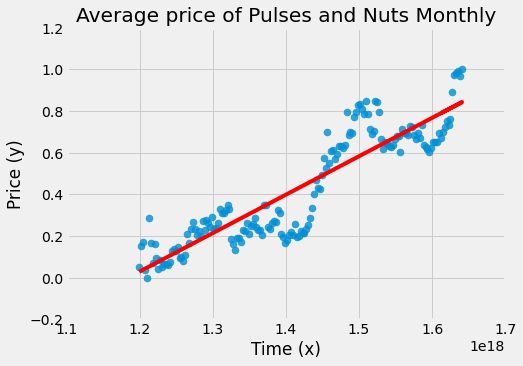

In [45]:
plt.figure(figsize=(7,5))
plt.scatter(X, y, marker= 'o', s=50, alpha=0.8)
plt.plot(X, DPNM_linreg.coef_ * X + DPNM_linreg.intercept_, 'r-')
plt.title('Average price of Pulses and Nuts Monthly')
plt.xlabel('Time (x)')
plt.ylabel('Price (y)')
plt.show()

In [46]:
DPNM_linear_predict = pd.DataFrame(pd.date_range(start=pred_st_date,end=pred_end_date, freq='MS').to_pydatetime().tolist(), columns=['date'])
DPNM_linear_predict['time'] = DPNM_linear_predict['date'].apply(lambda x: x.value)
DPNM_linear_predict

,date,time
0,2009-01-01,1230768000000000000
1,2009-02-01,1233446400000000000
2,2009-03-01,1235865600000000000
3,2009-04-01,1238544000000000000
4,2009-05-01,1241136000000000000
...,...,...
188,2024-09-01,1725148800000000000
189,2024-10-01,1727740800000000000
190,2024-11-01,1730419200000000000
191,2024-12-01,1733011200000000000


In [47]:
time_predict = np.array(DPNM_linear_predict['time']).reshape((-1, 1))
DPNM_linear_predict['price'] = DPNM_linreg.predict(time_predict)
DPNM_linear_predict

,date,time,price
0,2009-01-01,1230768000000000000,0.086373
1,2009-02-01,1233446400000000000,0.091311
2,2009-03-01,1235865600000000000,0.095771
3,2009-04-01,1238544000000000000,0.100710
4,2009-05-01,1241136000000000000,0.105489
...,...,...,...
188,2024-09-01,1725148800000000000,0.997882
189,2024-10-01,1727740800000000000,1.002661
190,2024-11-01,1730419200000000000,1.007599
191,2024-12-01,1733011200000000000,1.012378


In [48]:
DPNM_linear_normalized_predict = DPNM_linear_predict.copy()
DPNM_linear_normalized_predict = DPNM_linear_normalized_predict[['date', 'price']]
DPNM_linear_normalized_predict.set_index('date', inplace=True)
DPNM_linear_normalized_predict

,price
date,
2009-01-01,0.086373
2009-02-01,0.091311
2009-03-01,0.095771
2009-04-01,0.100710
2009-05-01,0.105489
...,...
2024-09-01,0.997882
2024-10-01,1.002661
2024-11-01,1.007599


##### Unnormalized the data

In [49]:
DPNM_pred_act_linear = scaler.inverse_transform(DPNM_linear_normalized_predict)
DPNM_pred_act_linear_df = pd.DataFrame(DPNM_pred_act_linear)
DPNM_pred_act_linear_df['date'] = DPNM_linear_predict['date']
DPNM_pred_act_linear_df.columns = ['Predicted Price (KG)', 'date']
DPNM_pred_act_linear_df.set_index('date', inplace=True)
DPNM_pred_act_linear_df

,Predicted Price (KG)
date,
2009-01-01,682.611504
2009-02-01,691.274427
2009-03-01,699.099002
2009-04-01,707.761925
2009-05-01,716.145399
...,...
2024-09-01,2281.619429
2024-10-01,2290.002903
2024-11-01,2298.665826
